In [5]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import plotly

pd.options.plotting.backend = 'plotly'

In [6]:
import kagglehub

# Download latest version
path = kagglehub.dataset_download("redwankarimsony/heart-disease-data")

print("Path to dataset files:", path)

Path to dataset files: C:\Users\LEGION\.cache\kagglehub\datasets\redwankarimsony\heart-disease-data\versions\6


In [7]:
import os

# List files in the directory to find the CSV file
files = os.listdir(path)

# Assuming there's only one CSV file or the first one is the intended one
csv_files = [f for f in files if f.endswith('.csv')]

if csv_files:
    csv_file_path = os.path.join(path, csv_files[0])
    df = pd.read_csv(csv_file_path)


# Exploratory Data Analysis

In [8]:
df.head()

,id,age,sex,dataset,cp,trestbps,chol,fbs,restecg,thalch,exang,oldpeak,slope,ca,thal,num
0,1,63,Male,Cleveland,typical angina,145.0,233.0,True,lv hypertrophy,150.0,False,2.3,downsloping,0.0,fixed defect,0
1,2,67,Male,Cleveland,asymptomatic,160.0,286.0,False,lv hypertrophy,108.0,True,1.5,flat,3.0,normal,2
2,3,67,Male,Cleveland,asymptomatic,120.0,229.0,False,lv hypertrophy,129.0,True,2.6,flat,2.0,reversable defect,1
3,4,37,Male,Cleveland,non-anginal,130.0,250.0,False,normal,187.0,False,3.5,downsloping,0.0,normal,0
4,5,41,Female,Cleveland,atypical angina,130.0,204.0,False,lv hypertrophy,172.0,False,1.4,upsloping,0.0,normal,0


In [9]:
import plotly.express as px

# Calculate mean and median
age_mean = df['age'].mean()
age_median = df['age'].median()

# Map colors: Male -> blue, Female -> pink
color_discrete_map = {'Male': 'navy', 'Female': 'pink'}

# Create the histogram with sex breakdown
fig = px.histogram(df, x='age', color='sex', title='Distribution of Age by Sex',
                   labels={'age': 'Age', 'count': 'Frequency', 'sex': 'Sex'},
                   color_discrete_map=color_discrete_map)

# Add mean line
fig.add_vline(x=age_mean, line_dash="dash", line_color="red",
              annotation_text=f"Mean: {age_mean:.2f}",
              annotation_position="top right")

# Add median line
fig.add_vline(x=age_median, line_dash="dash", line_color="green",
              annotation_text=f"Median: {age_median:.2f}",
              annotation_position="top left")

fig.update_layout(bargap=0.1, barmode='stack') # 'stack' places bars on top of each other
fig.show()
# Here the mean and median age is around 54

In [10]:
df.groupby('dataset').size().rename('count_of_rows').reset_index()

,dataset,count_of_rows
0,Cleveland,304
1,Hungary,293
2,Switzerland,123
3,VA Long Beach,200


In [11]:
df.groupby('sex').size().rename('count').reset_index()

,sex,count
0,Female,194
1,Male,726


In [12]:
df.isna().sum()

id            0
age           0
sex           0
dataset       0
cp            0
trestbps     59
chol         30
fbs          90
restecg       2
thalch       55
exang        55
oldpeak      62
slope       309
ca          611
thal        486
num           0
dtype: int64

In [13]:
df.groupby('cp').size()

cp
asymptomatic       496
atypical angina    174
non-anginal        204
typical angina      46
dtype: int64

In [14]:
# trestbps stands for resting blood pressure
# Make a histogram of trestbps
df['trestbps'].plot(kind='hist', title='Distribution of Resting Blood Pressure')
# Let's understand the missingness first
# There is a row where the trestbps is 0, probably an error, let's replace that will null

df.at[753, 'trestbps'] = pd.NA

In [15]:
import plotly.express as px

# Drop NAs for calculating mean/median correctly
trestbps_clean = df['trestbps'].dropna()
trestbps_mean = trestbps_clean.mean()
trestbps_median = trestbps_clean.median()

# Create the histogram with Plotly
fig = px.histogram(df, x='trestbps', title='Distribution of Resting Blood Pressure (trestbps)',
                   labels={'trestbps': 'Resting Blood Pressure (mm Hg)', 'count': 'Frequency'})

# Add mean line (red)
fig.add_vline(x=trestbps_mean, line_dash="dash", line_color="red",
              annotation_text=f"Mean: {trestbps_mean:.2f}",
              annotation_position="top right")

# Add median line (green)
fig.add_vline(x=trestbps_median, line_dash="dash", line_color="green",
              annotation_text=f"Median: {trestbps_median:.2f}",
              annotation_position="top left")

fig.update_layout(bargap=0.1)
fig.show()

I think that missing values of trestbps can be filled with the median

In [16]:
df

,id,age,sex,dataset,cp,trestbps,chol,fbs,restecg,thalch,exang,oldpeak,slope,ca,thal,num
0,1,63,Male,Cleveland,typical angina,145.0,233.0,True,lv hypertrophy,150.0,False,2.3,downsloping,0.0,fixed defect,0
1,2,67,Male,Cleveland,asymptomatic,160.0,286.0,False,lv hypertrophy,108.0,True,1.5,flat,3.0,normal,2
2,3,67,Male,Cleveland,asymptomatic,120.0,229.0,False,lv hypertrophy,129.0,True,2.6,flat,2.0,reversable defect,1
3,4,37,Male,Cleveland,non-anginal,130.0,250.0,False,normal,187.0,False,3.5,downsloping,0.0,normal,0
4,5,41,Female,Cleveland,atypical angina,130.0,204.0,False,lv hypertrophy,172.0,False,1.4,upsloping,0.0,normal,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
915,916,54,Female,VA Long Beach,asymptomatic,127.0,333.0,True,st-t abnormality,154.0,False,0.0,NaN,NaN,NaN,1
916,917,62,Male,VA Long Beach,typical angina,NaN,139.0,False,st-t abnormality,NaN,NaN,NaN,NaN,NaN,NaN,0
917,918,55,Male,VA Long Beach,asymptomatic,122.0,223.0,True,st-t abnormality,100.0,False,0.0,NaN,NaN,fixed defect,2
918,919,58,Male,VA Long Beach,asymptomatic,NaN,385.0,True,lv hypertrophy,NaN,NaN,NaN,NaN,NaN,NaN,0


In [17]:
# 1. Create a 10-year age bin column
# We can use pd.cut to group ages into 10-year intervals (e.g., 20-29, 30-39, etc.)
bins = list(range(10, 100, 10))
df['age_bin'] = pd.cut(df['age'], bins=bins, right=False)

# 2. Calculate the mean trestbps for each age bin & sex group
group_means = df.groupby(['age_bin', 'sex'], observed=False)['trestbps'].mean()
display(group_means.reset_index(name='mean_trestbps'))

,age_bin,sex,mean_trestbps
0,"[10, 20)",Female,NaN
1,"[10, 20)",Male,NaN
2,"[20, 30)",Female,NaN
3,"[20, 30)",Male,130.000000
4,"[30, 40)",Female,120.947368
5,"[30, 40)",Male,124.545455
6,"[40, 50)",Female,126.365385
7,"[40, 50)",Male,127.467949
8,"[50, 60)",Female,134.069444
9,"[50, 60)",Male,133.854093


In [18]:
# 3. Impute missing trestbps values using the group averages
# We fill missing values of trestbps with the corresponding group mean
df['trestbps'] = df['trestbps'].fillna(df.groupby(['age_bin', 'sex'], observed=False)['trestbps'].transform('mean'))

# Check if there are any remaining missing values in trestbps
print("Remaining missing values in trestbps:", df['trestbps'].isna().sum())
group_means = df.groupby(['age_bin', 'sex'], observed=False)['trestbps'].mean()
display(group_means.reset_index(name='mean_trestbps'))

Remaining missing values in trestbps: 0


,age_bin,sex,mean_trestbps
0,"[10, 20)",Female,NaN
1,"[10, 20)",Male,NaN
2,"[20, 30)",Female,NaN
3,"[20, 30)",Male,130.000000
4,"[30, 40)",Female,120.947368
5,"[30, 40)",Male,124.545455
6,"[40, 50)",Female,126.365385
7,"[40, 50)",Male,127.467949
8,"[50, 60)",Female,134.069444
9,"[50, 60)",Male,133.854093


In [19]:
# Impact of imputation
import plotly.express as px

# Drop NAs for calculating mean/median correctly
trestbps_clean = df['trestbps'].dropna()
trestbps_mean = trestbps_clean.mean()
trestbps_median = trestbps_clean.median()

# Create the histogram with Plotly
fig = px.histogram(df, x='trestbps', title='Distribution of Resting Blood Pressure (trestbps)',
                   labels={'trestbps': 'Resting Blood Pressure (mm Hg)', 'count': 'Frequency'})

# Add mean line (red)
fig.add_vline(x=trestbps_mean, line_dash="dash", line_color="red",
              annotation_text=f"Mean: {trestbps_mean:.2f}",
              annotation_position="top right")

# Add median line (green)
fig.add_vline(x=trestbps_median, line_dash="dash", line_color="green",
              annotation_text=f"Median: {trestbps_median:.2f}",
              annotation_position="top left")

fig.update_layout(bargap=0.1)
fig.show()

# Let's move to chol, EDA & Filling

In [20]:
# There are 172 rows where the chol is 0, which is biologically impossible, seems like bad data so we will fill it with null
df['chol'] = np.where(
    df['chol'] == 0,
    np.nan,
    df['chol']
)
df.chol.isna().sum()

np.int64(202)

In [21]:
import plotly.express as px

# Calculate the mean and median of cholesterol, ignoring missing values
chol_clean = df['chol'].dropna()
chol_mean = chol_clean.mean()
chol_median = chol_clean.median()

# Create a stacked histogram of 'chol' colored by 'age_bin'
fig = px.histogram(
    df,
    x='chol',
    color='age_bin',
    title='Distribution of Cholesterol (chol) by Age Bin',
    labels={'chol': 'Cholesterol (mg/dl)', 'count': 'Frequency', 'age_bin': 'Age Bin'},
    category_orders={'age_bin': sorted(df['age_bin'].dropna().unique().astype(str))}
)

# Add a vertical line for the mean
fig.add_vline(
    x=chol_mean,
    line_dash="dash",
    line_color="red",
    annotation_text=f"Mean: {chol_mean:.2f}",
    annotation_position="top right"
)

# Add a vertical line for the median
fig.add_vline(
    x=chol_median,
    line_dash="dash",
    line_color="green",
    annotation_text=f"Median: {chol_median:.2f}",
    annotation_position="top left"
)

fig.update_layout(bargap=0.1, barmode='stack')
fig.show()

# EDA & Impute FBS

In [22]:
df['fbs'].value_counts(normalize=True)

fbs
False    0.833735
True     0.166265
Name: proportion, dtype: float64

In [23]:
pd.crosstab(df['fbs'], df['num'], normalize='index')

num,0,1,2,3,4
fbs,,,,,
False,0.510116,0.268786,0.093931,0.096821,0.030347
True,0.318841,0.282609,0.166667,0.195652,0.036232


In [24]:
df[df['fbs'].isna()].groupby('dataset').size()

dataset
Hungary           8
Switzerland      75
VA Long Beach     7
dtype: int64

In [25]:
# Let's add an unknown class to the missing fbs

df['fbs'] = df['fbs'].fillna('Unknown')

# restecg

In [26]:
print(df.restecg.isna().sum())
df = df.dropna(subset=['restecg'])

2


# thalach: Maximum heart rate acheived

In [27]:
# Calculate mean and median for thalch, ignoring missing values
thalch_clean = df['thalch'].dropna()
thalch_mean = thalch_clean.mean()
thalch_median = thalch_clean.median()

# Create a stacked histogram of 'thalch' colored by 'age_bin'
fig = px.histogram(
    df,
    x='thalch',
    color='age_bin',
    title='Distribution of Maximum Heart Rate Achieved (thalch) by Age Bin',
    labels={'thalch': 'Maximum Heart Rate (thalch)', 'count': 'Frequency', 'age_bin': 'Age Bin'},
    category_orders={'age_bin': sorted(df['age_bin'].dropna().unique().astype(str))}
)

# Add vertical line for the mean
fig.add_vline(
    x=thalch_mean,
    line_dash="dash",
    line_color="red",
    annotation_text=f"Mean: {thalch_mean:.2f}",
    annotation_position="top right"
)

# Add vertical line for the median
fig.add_vline(
    x=thalch_median,
    line_dash="dash",
    line_color="green",
    annotation_text=f"Median: {thalch_median:.2f}",
    annotation_position="top left"
)

fig.update_layout(bargap=0.1, barmode='stack')
fig.show()

In [28]:
# There are a total of 55 missing rows
thalch_lookup_table = df.groupby('age_bin').agg(
    num_missing=('thalch', lambda x: x.isna().sum()),
    num_rows=('thalch', 'count'),
    mean_value = ('thalch', 'mean'),
    median_value = ('thalch', 'median'),
    max_value = ('thalch', 'max'),
    min_value = ('thalch', 'min')
).reset_index()



In [29]:
# Use groupby transform to fill missing thalch values with the median of their age_bin
df['thalch'] = df['thalch'].fillna(df.groupby('age_bin', observed=False)['thalch'].transform('mean'))

# Verify that there are no remaining missing values in thalch
print("Remaining missing values in thalch:", df['thalch'].isna().sum())

Remaining missing values in thalch: 0


# exang: Exercise induced angina

### Diagnostic 1: Hospital Source Profiling for `exang`

In [30]:
# Group the missing exang rows by the dataset column to see if they are localized
missing_exang_by_dataset = df[df['exang'].isna()].groupby('dataset').size().rename('missing_count').reset_index()
display(missing_exang_by_dataset)

,dataset,missing_count
0,Hungary,1
1,Switzerland,1
2,VA Long Beach,53


### Diagnostic 2: Clinical Cross-Checking (`exang` vs. `cp`)

In [31]:
# Cross-tabulate exang against cp (chest pain type) for available data
cp_exang_crosstab = pd.crosstab(df['cp'], df['exang'], margins=True)
display(cp_exang_crosstab)

exang,False,True,All
cp,,,
asymptomatic,193,276,469
atypical angina,151,16,167
non-anginal,146,40,186
typical angina,36,5,41
All,526,337,863


### Diagnostic 3: Target Distribution Analysis (`exang` vs. `num`)

In [32]:
# Contingency table of exang against the target variable num
target_exang_crosstab = pd.crosstab(df['num'], df['exang'], normalize='index')
display(target_exang_crosstab)

exang,False,True
num,,
0,0.859335,0.140665
1,0.420000,0.580000
2,0.431373,0.568627
3,0.319149,0.680851
4,0.423077,0.576923


In [33]:
# Let's just add another category called "unknown" and impute the missing data with that
df['exang'] = df['exang'].fillna('unknown')

# Oldpeak: ST depression induced by exercise relative to rest

In [34]:
# There are a total of 62 rows where oldpeak is null
df.oldpeak.isna().sum()

np.int64(62)

In [35]:
import plotly.express as px

# Calculate mean and median for oldpeak, ignoring missing values
oldpeak_clean = df['oldpeak'].dropna()
oldpeak_mean = oldpeak_clean.mean()
oldpeak_median = oldpeak_clean.median()

# Create a stacked histogram of 'oldpeak' colored by 'age_bin'
fig = px.histogram(
    df,
    x='oldpeak',
    color='age_bin',
    title='Distribution of ST Depression (oldpeak) by Age Bin',
    labels={'oldpeak': 'ST Depression (oldpeak)', 'count': 'Frequency', 'age_bin': 'Age Bin'},
    category_orders={'age_bin': sorted(df['age_bin'].dropna().unique().astype(str))}
)

# Add vertical line for the mean
fig.add_vline(
    x=oldpeak_mean,
    line_dash="dash",
    line_color="red",
    annotation_text=f"Mean: {oldpeak_mean:.2f}",
    annotation_position="top right"
)

# Add vertical line for the median
fig.add_vline(
    x=oldpeak_median,
    line_dash="dash",
    line_color="green",
    annotation_text=f"Median: {oldpeak_median:.2f}",
    annotation_position="top left"
)

fig.update_layout(bargap=0.1, barmode='stack')
fig.show()

### Diagnostic 1: Hospital Source Profiling for `oldpeak`

In [36]:
# Profile where the missing oldpeak values reside across datasets
missing_oldpeak_by_dataset = df[df['oldpeak'].isna()].groupby('dataset').size().rename('missing_count').reset_index()
display(missing_oldpeak_by_dataset)

,dataset,missing_count
0,Switzerland,6
1,VA Long Beach,56


In [37]:
# Create a boxplot of oldpeak against the target variable num
fig = px.box(
    df,
    x='num',
    y='oldpeak',
    title='ST Depression (oldpeak) Distribution across Disease Severity (num)',
    labels={'num': 'Disease Severity (num)', 'oldpeak': 'ST Depression (oldpeak)'},
    color='num'
)

fig.update_layout(showlegend=False)
fig.show()

In [38]:
# Create a boxplot to show the relationship between oldpeak and slope
fig = px.box(
    df,
    x='slope',
    y='oldpeak',
    title='Relationship between ST Depression (oldpeak) and ST Slope (slope)',
    labels={'slope': 'ST Segment Slope (slope)', 'oldpeak': 'ST Depression (oldpeak)'},
    color='slope',
    category_orders={'slope': ['upsloping', 'flat', 'downsloping']}
)

fig.update_layout(showlegend=False)
fig.show()

In [39]:
df[df['slope'].isna()].oldpeak .isna().sum()
# Although there is a clear relationship between the oldpeak and the slope, both of them are nulls at the same location

np.int64(62)

# CA: Number of major vessels (0-3) colored by fluoroscopy

In [40]:
df.ca.isna().sum()

np.int64(609)

In [41]:
df.groupby('sex')['ca'].mean()

sex
Female    0.546392
Male      0.735849
Name: ca, dtype: float64

# EDA

In [42]:
# Age distribution, colored by sex
import plotly.express as px

# Calculate mean and median
age_mean = df['age'].mean()
age_median = df['age'].median()

# Map colors: Male -> blue, Female -> pink
color_discrete_map = {'Male': 'navy', 'Female': 'pink'}

# Create the histogram with sex breakdown
fig = px.histogram(df, x='age', color='sex', title='Distribution of Age by Sex',
                   labels={'age': 'Age', 'count': 'Frequency', 'sex': 'Sex'},
                   color_discrete_map=color_discrete_map)

# Add mean line
fig.add_vline(x=age_mean, line_dash="dash", line_color="red",
              annotation_text=f"Mean: {age_mean:.2f}",
              annotation_position="top right")

# Add median line
fig.add_vline(x=age_median, line_dash="dash", line_color="green",
              annotation_text=f"Median: {age_median:.2f}",
              annotation_position="top left")

fig.update_layout(bargap=0.1, barmode='stack') # 'stack' places bars on top of each other
fig.show()
# Here the mean and median age is around 54

In [43]:
# Create a boxplot to visualize the relationship between age and chest pain type (cp)
fig = px.box(
    df,
    x='cp',
    y='age',
    title='Relationship between Age and Chest Pain Type (cp)',
    labels={'cp': 'Chest Pain Type (cp)', 'age': 'Age'},
    color='cp',
    category_orders={'cp': ['typical angina', 'atypical angina', 'non-anginal', 'asymptomatic']}
)

fig.update_layout(showlegend=False)
fig.show()

Trestbps

In [44]:
import plotly.express as px

# Ensure consistent ordering for the age bin groups in the legend
age_bin_order = sorted(df['age_bin'].dropna().unique().astype(str))

# Create a stacked histogram for resting blood pressure (trestbps) segmented by age_bin
fig = px.histogram(
    df,
    x='trestbps',
    color='age_bin',
    title='Stacked Distribution of Resting Blood Pressure (trestbps) by Age Bin',
    labels={'trestbps': 'Resting Blood Pressure (mm Hg)', 'count': 'Frequency', 'age_bin': 'Age Bin'},
    category_orders={'age_bin': age_bin_order}
)

# Force visual bar spacing and ensure stacking mode
fig.update_layout(bargap=0.1, barmode='stack')
fig.show()

In [46]:
import plotly.express as px

# Create a scatter plot of age vs. resting blood pressure
fig = px.scatter(
    df,
    x='age',
    y='trestbps',
    trendline='ols',
    title='Relationship between Age and Resting Blood Pressure (trestbps)',
    labels={'age': 'Age (Years)', 'trestbps': 'Resting Blood Pressure (mm Hg)'},
    opacity=0.6
)

fig.show()

### Summary of Resting Blood Pressure (trestbps)
* **Mean Resting Blood Pressure:** ~132.45 mm Hg
* **Median Resting Blood Pressure:** 130.00 mm Hg

In [47]:
import plotly.express as px

# Create the heart_disease column avoiding the SettingWithCopyWarning
df.loc[:, 'heart_disease'] = df['num'] != 0

# Plot the relationship between heart_disease and trestbps
fig = px.box(
    df,
    x='heart_disease',
    y='trestbps',
    color='heart_disease',
    title='Resting Blood Pressure (trestbps) by Heart Disease Status',
    labels={'heart_disease': 'Has Heart Disease', 'trestbps': 'Resting Blood Pressure (mm Hg)'}
)

fig.update_layout(showlegend=False)
fig.show()

In [48]:
import plotly.express as px

# Plot the relationship between heart_disease and age
fig = px.box(
    df,
    x='heart_disease',
    y='age',
    color='heart_disease',
    title='Age Distribution by Heart Disease Status',
    labels={'heart_disease': 'Has Heart Disease', 'age': 'Age (Years)'}
)

fig.update_layout(showlegend=False)
fig.show()

EDA on cholestrol

In [49]:
import plotly.express as px

# Calculate mean and median for cholesterol ignoring NaNs
chol_clean = df['chol'].dropna()
chol_mean = chol_clean.mean()
chol_median = chol_clean.median()

# Sort age bins for a consistent legend ordering
age_bin_order = sorted(df['age_bin'].dropna().unique().astype(str))

# Create the stacked histogram
fig = px.histogram(
    df,
    x='chol',
    color='age_bin',
    title='Distribution of Cholesterol (chol) by Age Bin',
    labels={'chol': 'Cholesterol (mg/dl)', 'count': 'Frequency', 'age_bin': 'Age Bin'},
    category_orders={'age_bin': age_bin_order}
)

# Add vertical line for the mean
fig.add_vline(
    x=chol_mean,
    line_dash="dash",
    line_color="red",
    annotation_text=f"Mean: {chol_mean:.2f}",
    annotation_position="top right"
)

# Add vertical line for the median
fig.add_vline(
    x=chol_median,
    line_dash="dash",
    line_color="green",
    annotation_text=f"Median: {chol_median:.2f}",
    annotation_position="top left"
)

fig.update_layout(bargap=0.1, barmode='stack')
fig.show()

In [50]:
import plotly.express as px

# Create a scatter plot of age vs. cholesterol
fig = px.scatter(
    df,
    x='age',
    y='chol',
    trendline='ols',
    title='Relationship between Age and Cholesterol (chol)',
    labels={'age': 'Age (Years)', 'chol': 'Cholesterol (mg/dl)'},
    opacity=0.6
)

fig.show()

In [51]:
import plotly.express as px

# Plot the relationship between heart_disease and chol (cholesterol)
fig = px.box(
    df,
    x='heart_disease',
    y='chol',
    color='heart_disease',
    title='Cholesterol (chol) Distribution by Heart Disease Status',
    labels={'heart_disease': 'Has Heart Disease', 'chol': 'Cholesterol (mg/dl)'}
)

fig.update_layout(showlegend=False)
fig.show()

FBS

In [52]:
df

,id,age,sex,dataset,cp,trestbps,chol,fbs,restecg,thalch,exang,oldpeak,slope,ca,thal,num,age_bin,heart_disease
0,1,63,Male,Cleveland,typical angina,145.000000,233.0,True,lv hypertrophy,150.000000,False,2.3,downsloping,0.0,fixed defect,0,"[60, 70)",False
1,2,67,Male,Cleveland,asymptomatic,160.000000,286.0,False,lv hypertrophy,108.000000,True,1.5,flat,3.0,normal,2,"[60, 70)",True
2,3,67,Male,Cleveland,asymptomatic,120.000000,229.0,False,lv hypertrophy,129.000000,True,2.6,flat,2.0,reversable defect,1,"[60, 70)",True
3,4,37,Male,Cleveland,non-anginal,130.000000,250.0,False,normal,187.000000,False,3.5,downsloping,0.0,normal,0,"[30, 40)",False
4,5,41,Female,Cleveland,atypical angina,130.000000,204.0,False,lv hypertrophy,172.000000,False,1.4,upsloping,0.0,normal,0,"[40, 50)",False
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
915,916,54,Female,VA Long Beach,asymptomatic,127.000000,333.0,True,st-t abnormality,154.000000,False,0.0,NaN,NaN,NaN,1,"[50, 60)",True
916,917,62,Male,VA Long Beach,typical angina,136.033113,139.0,False,st-t abnormality,127.811224,unknown,NaN,NaN,NaN,NaN,0,"[60, 70)",False
917,918,55,Male,VA Long Beach,asymptomatic,122.000000,223.0,True,st-t abnormality,100.000000,False,0.0,NaN,NaN,fixed defect,2,"[50, 60)",True
918,919,58,Male,VA Long Beach,asymptomatic,133.854093,385.0,True,lv hypertrophy,134.841808,unknown,NaN,NaN,NaN,NaN,0,"[50, 60)",False


In [53]:
import pandas as pd
import plotly.express as px

# 1. Confusion Matrix (Contingency Table) of fbs vs heart_disease
fbs_hd_ct = pd.crosstab(df['fbs'], df['heart_disease'])

fig1 = px.imshow(
    fbs_hd_ct,
    text_auto=True,
    color_continuous_scale='Blues',
    title='Confusion Matrix (Contingency Table): fbs vs. heart_disease',
    labels=dict(x="Has Heart Disease", y="Fasting Blood Sugar > 120 mg/dl (fbs)", color="Count")
)
fig1.show()

In [54]:
import numpy as np
import pandas as pd
import plotly.express as px

# Define bins and labels for cholesterol levels
chol_bins = [0, 200, 240, 280, np.inf]
chol_labels = ['normal', 'mildly elevated', 'elevated', 'highly elevated']

# Bin cholesterol and convert directly to string series to avoid categorical dtype deprecation warnings
binned_chol = pd.cut(df['chol'], bins=chol_bins, labels=chol_labels, right=False)
df.loc[:, 'chol_levels'] = binned_chol.astype(str).replace('nan', 'unknown')

# 2. Confusion Matrix of fbs vs chol_levels
fbs_chol_ct = pd.crosstab(df['fbs'], df['chol_levels'])

fig2 = px.imshow(
    fbs_chol_ct,
    text_auto=True,
    color_continuous_scale='Purples',
    title='Confusion Matrix (Contingency Table): fbs vs. chol_levels',
    labels=dict(x="Cholesterol Levels (chol_levels)", y="Fasting Blood Sugar (fbs)", color="Count")
)
fig2.show()

In [55]:
import numpy as np
import pandas as pd
import plotly.express as px

# Define clinical boundaries and labels for resting blood pressure (trestbps)
bp_bins = [0, 120, 130, 140, np.inf]
bp_labels = ['normal', 'elevated', 'stage 1 hypertension', 'stage 2 hypertension']

# Categorize resting blood pressure cleanly to avoid SettingWithCopyWarning
binned_bp = pd.cut(df['trestbps'], bins=bp_bins, labels=bp_labels, right=False)
df = df.copy()  # Ensure we have an explicit copy of the dataframe
df['bp_levels'] = binned_bp.astype(str).replace('nan', 'unknown')

# Calculate the contingency table of fbs vs. bp_levels
fbs_bp_ct = pd.crosstab(df['fbs'], df['bp_levels'])

# Visualize the relationship with an interactive Plotly imshow heatmap
fig3 = px.imshow(
    fbs_bp_ct,
    text_auto=True,
    color_continuous_scale='Greens',
    title='Confusion Matrix (Contingency Table): fbs vs. bp_levels',
    labels=dict(x="Blood Pressure Levels (bp_levels)", y="Fasting Blood Sugar (fbs)", color="Count")
)
fig3.show()

restecg

In [56]:
import pandas as pd
import plotly.express as px

# Calculate the contingency table (confusion matrix) of restecg vs. heart_disease
restecg_hd_ct = pd.crosstab(df['restecg'], df['heart_disease'])

# Visualize the relationship with an interactive Plotly imshow heatmap
fig_restecg = px.imshow(
    restecg_hd_ct,
    text_auto=True,
    color_continuous_scale='Oranges',
    title='Confusion Matrix (Contingency Table): restecg vs. heart_disease',
    labels=dict(x="Has Heart Disease", y="Resting ECG Result (restecg)", color="Count")
)
fig_restecg.show()

In [57]:
import plotly.express as px

# Create a box plot to examine trestbps across restecg categories
fig_sanity = px.box(
    df,
    x='restecg',
    y='trestbps',
    color='restecg',
    title='Resting Blood Pressure (trestbps) by Resting ECG Category (restecg)',
    labels={'restecg': 'Resting ECG Result (restecg)', 'trestbps': 'Resting Blood Pressure (mm Hg)'},
    category_orders={'restecg': ['normal', 'st-t abnormality', 'lv hypertrophy']}
)

fig_sanity.update_layout(showlegend=False)
fig_sanity.show()

thalch: Maximum Heart Rate Acheived.

In [58]:
import plotly.express as px

# Sort age bins for a consistent legend ordering
age_bin_order = sorted(df['age_bin'].dropna().unique().astype(str))

# 1. Histogram of thalch, colored by age bin
fig_thalch_hist = px.histogram(
    df,
    x='thalch',
    color='age_bin',
    title='Distribution of Maximum Heart Rate (thalch) by Age Bin',
    labels={'thalch': 'Maximum Heart Rate Achieved (thalch)', 'count': 'Frequency', 'age_bin': 'Age Bin'},
    category_orders={'age_bin': age_bin_order}
)
fig_thalch_hist.update_layout(bargap=0.1, barmode='stack')
fig_thalch_hist.show()

In [59]:
# 2. Age vs thalch scatterplot
fig_age_thalch = px.scatter(
    df,
    x='age',
    y='thalch',
    trendline='ols',
    title='Relationship between Age and Maximum Heart Rate (thalch)',
    labels={'age': 'Age (Years)', 'thalch': 'Maximum Heart Rate Achieved (thalch)'},
    opacity=0.6
)
fig_age_thalch.show()

In [60]:
# 3. Relationship between thalch and heart disease using a box plot
fig_thalch_hd = px.box(
    df,
    x='heart_disease',
    y='thalch',
    color='heart_disease',
    title='Maximum Heart Rate (thalch) by Heart Disease Status',
    labels={'heart_disease': 'Has Heart Disease', 'thalch': 'Maximum Heart Rate Achieved (thalch)'}
)
fig_thalch_hd.update_layout(showlegend=False)
fig_thalch_hd.show()

# exang: Exercise Induced Angina

In [61]:
df

,id,age,sex,dataset,cp,trestbps,chol,fbs,restecg,thalch,exang,oldpeak,slope,ca,thal,num,age_bin,heart_disease,chol_levels,bp_levels
0,1,63,Male,Cleveland,typical angina,145.000000,233.0,True,lv hypertrophy,150.000000,False,2.3,downsloping,0.0,fixed defect,0,"[60, 70)",False,mildly elevated,stage 2 hypertension
1,2,67,Male,Cleveland,asymptomatic,160.000000,286.0,False,lv hypertrophy,108.000000,True,1.5,flat,3.0,normal,2,"[60, 70)",True,highly elevated,stage 2 hypertension
2,3,67,Male,Cleveland,asymptomatic,120.000000,229.0,False,lv hypertrophy,129.000000,True,2.6,flat,2.0,reversable defect,1,"[60, 70)",True,mildly elevated,elevated
3,4,37,Male,Cleveland,non-anginal,130.000000,250.0,False,normal,187.000000,False,3.5,downsloping,0.0,normal,0,"[30, 40)",False,elevated,stage 1 hypertension
4,5,41,Female,Cleveland,atypical angina,130.000000,204.0,False,lv hypertrophy,172.000000,False,1.4,upsloping,0.0,normal,0,"[40, 50)",False,mildly elevated,stage 1 hypertension
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
915,916,54,Female,VA Long Beach,asymptomatic,127.000000,333.0,True,st-t abnormality,154.000000,False,0.0,NaN,NaN,NaN,1,"[50, 60)",True,highly elevated,elevated
916,917,62,Male,VA Long Beach,typical angina,136.033113,139.0,False,st-t abnormality,127.811224,unknown,NaN,NaN,NaN,NaN,0,"[60, 70)",False,normal,stage 1 hypertension
917,918,55,Male,VA Long Beach,asymptomatic,122.000000,223.0,True,st-t abnormality,100.000000,False,0.0,NaN,NaN,fixed defect,2,"[50, 60)",True,mildly elevated,elevated
918,919,58,Male,VA Long Beach,asymptomatic,133.854093,385.0,True,lv hypertrophy,134.841808,unknown,NaN,NaN,NaN,NaN,0,"[50, 60)",False,highly elevated,stage 1 hypertension


In [62]:
import pandas as pd
import plotly.express as px

# 1. Plot the relationship between exang & restecg using a contingency table (confusion matrix)
exang_restecg_ct = pd.crosstab(df['exang'], df['restecg'])

fig_exang_restecg = px.imshow(
    exang_restecg_ct,
    text_auto=True,
    color_continuous_scale='Teal',
    title='Confusion Matrix (Contingency Table): exang vs. restecg',
    labels=dict(x="Resting ECG Result (restecg)", y="Exercise Induced Angina (exang)", color="Count")
)
fig_exang_restecg.show()

In [63]:
# 2. Plot the relationship between exang vs heart_disease
exang_hd_ct = pd.crosstab(df['exang'], df['heart_disease'])

fig_exang_hd = px.imshow(
    exang_hd_ct,
    text_auto=True,
    color_continuous_scale='Reds',
    title='Confusion Matrix (Contingency Table): exang vs. heart_disease',
    labels=dict(x="Has Heart Disease (heart_disease)", y="Exercise Induced Angina (exang)", color="Count")
)
fig_exang_hd.show()

# Slope & Old Peak

In [64]:

import plotly.express as px
import plotly.graph_objects as go
import pandas as pd

# 1. Box plot: Slope vs Oldpeak
fig1 = px.box(
    df,
    x="slope",
    y="oldpeak",
    color="slope",
    title="Distribution of Oldpeak Across Slope Categories",
    labels={
        "slope": "Slope",
        "oldpeak": "Oldpeak"
    },
    points="outliers"
)

fig1.update_layout(

    showlegend=False
)
fig1.show()


# 2. Box plot: Oldpeak vs Heart Disease
fig2 = px.box(
    df,
    x="heart_disease",
    y="oldpeak",
    color="heart_disease",
    title="Oldpeak Distribution by Heart Disease",
    labels={
        "heart_disease": "Heart Disease",
        "oldpeak": "Oldpeak"
    },
    points="outliers"
)

fig2.update_layout(

    showlegend=False,
    xaxis=dict(
        tickvals=[False, True],
        ticktext=["No Heart Disease", "Heart Disease"]
    )
)
fig2.show()


# 3. Slope vs Heart Disease: Confusion-style Matrix
# Note: This is a contingency matrix, not a predictive
# model confusion matrix.

matrix = pd.crosstab(
    df["slope"],
    df["heart_disease"]
)

# Ensure both Boolean categories appear
matrix = matrix.reindex(
    columns=[False, True],
    fill_value=0
)

fig3 = px.imshow(
    matrix,
    text_auto=True,
    color_continuous_scale="Blues",
    title="Slope vs Heart Disease",
    labels={
        "x": "Heart Disease",
        "y": "Slope",
        "color": "Patient Count"
    },
    aspect="auto"
)

fig3.update_layout(

    xaxis=dict(
        tickvals=[0, 1],
        ticktext=["No Heart Disease", "Heart Disease"]
    )
)
fig3.show()

Next up:
1. Data Preprocessing
2. Feature engineering
3. Modelling
4. Go back to step 2

In [65]:
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.experimental import enable_iterative_imputer
from sklearn.impute import IterativeImputer
from sklearn.preprocessing import RobustScaler

# Step 1: Make a copy of df and drop the 'ca' column
df_processed = df.copy()
df_processed = df_processed.drop(columns=['ca'])

In [66]:
# Step 2: Fill 'thal' missing values with the string 'Unknown' (or 'null') to treat it as a distinct category
df_processed['thal'] = df_processed['thal'].fillna('Unknown')

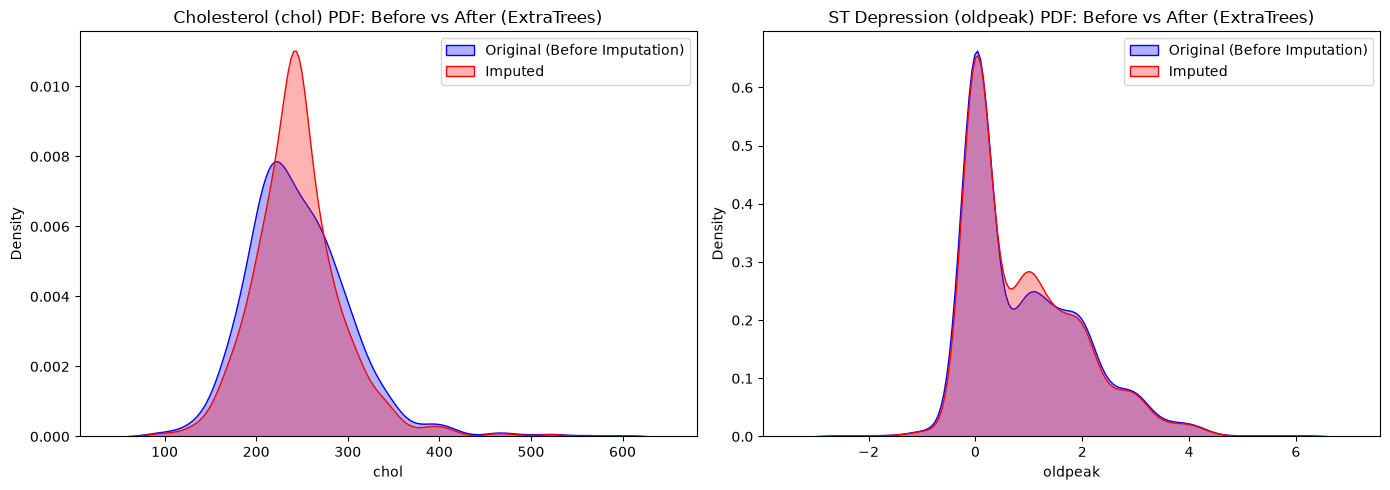

In [67]:
# Step 3: Iterative imputation for 'chol' and 'oldpeak' with before/after PDF plots
from sklearn.ensemble import ExtraTreesRegressor

# Save the original distributions (dropping NaNs) for the baseline plot
original_chol = df_processed['chol'].dropna()
original_oldpeak = df_processed['oldpeak'].dropna()

# Isolate numerical columns to provide mathematical context for the IterativeImputer
num_cols = ['chol', 'oldpeak']

# Initialize IterativeImputer with a non-linear, tree-based estimator
imputer = IterativeImputer(
    estimator=ExtraTreesRegressor(n_estimators=50, random_state=42),
    max_iter=10,
    random_state=42
)

# Apply the transformation
df_processed[num_cols] = imputer.fit_transform(df_processed[num_cols])

# Plot the Probability Density Functions (PDF)
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Cholesterol PDF
sns.kdeplot(original_chol, ax=axes[0], label='Original (Before Imputation)', color='blue', fill=True, alpha=0.3)
sns.kdeplot(df_processed['chol'], ax=axes[0], label='Imputed', color='red', fill=True, alpha=0.3)
axes[0].set_title('Cholesterol (chol) PDF: Before vs After (ExtraTrees)')
axes[0].legend()

# Oldpeak PDF
sns.kdeplot(original_oldpeak, ax=axes[1], label='Original (Before Imputation)', color='blue', fill=True, alpha=0.3)
sns.kdeplot(df_processed['oldpeak'], ax=axes[1], label='Imputed', color='red', fill=True, alpha=0.3)
axes[1].set_title('ST Depression (oldpeak) PDF: Before vs After (ExtraTrees)')
axes[1].legend()

plt.tight_layout()
plt.show()

In [68]:
df_processed.head(1)

,id,age,sex,dataset,cp,trestbps,chol,fbs,restecg,thalch,exang,oldpeak,slope,thal,num,age_bin,heart_disease,chol_levels,bp_levels
0,1,63,Male,Cleveland,typical angina,145.0,233.0,True,lv hypertrophy,150.0,False,2.3,downsloping,fixed defect,0,"[60, 70)",False,mildly elevated,stage 2 hypertension


In [69]:
# Drop the slope column as there's a lot of missing values there, idk how to deal with them
df_processed = df_processed.drop(columns=['slope'])

# Step 4: One-Hot Encoding

# Define categorical columns based on the dataset schema
cat_cols = ['sex', 'cp', 'fbs', 'restecg', 'exang', 'thal']

# If you have engineered columns like 'age_bin' or 'chol_levels' still in the df, include them dynamically
cat_cols = [col for col in cat_cols if col in df_processed.columns]

# Apply One-Hot Encoding using pd.get_dummies
# drop_first=True is mandatory for Logistic Regression to avoid the dummy variable trap (multicollinearity)
df_processed = pd.get_dummies(df_processed, columns=cat_cols, drop_first=True)

In [70]:
# # Step 5: Robust Scaling

# # Define the continuous variables that require scaling
# # We exclude the target ('num'), ID columns, and the newly created one-hot encoded boolean columns
# scale_cols = ['age', 'trestbps', 'chol', 'thalch', 'oldpeak']

# scaler = RobustScaler()
# df_processed[scale_cols] = scaler.fit_transform(df_processed[scale_cols])

# Modelling - Logistic Regression

In [71]:
df_model1 = df_processed.copy()

In [72]:
df_model1['ideal_max_hr'] = 220-df_model1['age']
# df_model1['max_hr_deflicit'] = df_model1['ideal_max_hr'] - df_model1['thalch'] - This seems to have no effect
# df_model1['rpp'] = df_model1['trestbps'] * df_model1['thalch'] - RPP seemed to increase the error

In [73]:
from sklearn.model_selection import train_test_split, GridSearchCV, StratifiedKFold
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import classification_report, confusion_matrix, roc_auc_score
import plotly.express as px

# 1. Convert target to strict binary classification
# 0 = No Disease, 1 = Disease
df_model1['heart_disease_binary'] = df_model1['num'].apply(lambda x: 1 if x > 0 else 0)

# Separate features (X) and target (y)
cols_to_drop = ['num', 'heart_disease_binary', 'id', 'dataset', 'heart_disease', 'ideal_max_hr']
X = df_model1.drop(columns=[col for col in cols_to_drop if col in df_model1.columns])
y = df_model1['heart_disease_binary']

# 2. Stratified Train-Test Split
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, stratify=y, random_state=42
)

print("X_train shape:", X_train.shape)
print("X_test shape:", X_test.shape)

X_train shape: (734, 21)
X_test shape: (184, 21)


In [74]:
from sklearn.preprocessing import StandardScaler

# Identify numerical columns for scaling
# Based on the features in X (dropping engineered categoricals if any)
scale_cols = ['age', 'trestbps', 'chol', 'thalch', 'oldpeak']
scale_cols = [col for col in scale_cols if col in X_train.columns]

# Scale features dynamically
scaler = StandardScaler()
X_train_scaled = X_train.copy()
X_test_scaled = X_test.copy()

X_train_scaled[scale_cols] = scaler.fit_transform(X_train[scale_cols])
X_test_scaled[scale_cols] = scaler.transform(X_test[scale_cols])

# For training, drop non-numeric/uncoded metadata columns that might remain in X
cols_to_drop_final = ['age_bin', 'chol_levels', 'bp_levels']

X_train_final = X_train_scaled.drop(columns=[c for c in cols_to_drop_final if c in X_train_scaled.columns])
X_test_final = X_test_scaled.drop(columns=[c for c in cols_to_drop_final if c in X_test_scaled.columns])

# Verify final shape
print("Final training features shape:", X_train_final.shape)

Final training features shape: (734, 18)


In [75]:
# 3. Model Training & Hyperparameter Tuning
# We'll use GridSearchCV to find the optimal regularization strength (C) and penalty

param_grid = {
    'C': [0.001, 0.01, 0.1, 1, 10, 100],
    'penalty': ['l2', 'l1'],
    'solver': ['liblinear']  # 'liblinear' supports both l1 and l2
}

# Setup Stratified K-Fold for validation
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

log_reg = LogisticRegression(max_iter=1000, random_state=42)
grid_search = GridSearchCV(estimator=log_reg, param_grid=param_grid, cv=cv, scoring='roc_auc', n_jobs=-1)
grid_search.fit(X_train_final, y_train)

# Best parameters
best_model = grid_search.best_estimator_
print("Best Parameters found:", grid_search.best_params_)
print(f"Best CV ROC-AUC: {grid_search.best_score_:.4f}")

Best Parameters found: {'C': 10, 'penalty': 'l2', 'solver': 'liblinear'}
Best CV ROC-AUC: 0.8808


d:\Projects\Data Science\Heart Disease Prediction\.venv\Lib\site-packages\sklearn\linear_model\_logistic.py:1381: FutureWarning: 'penalty' was deprecated in version 1.8 and will be removed in 1.10. To avoid this warning, leave 'penalty' set to its default value and use 'l1_ratio' or 'C' instead. Use l1_ratio=0 instead of penalty='l2', l1_ratio=1 instead of penalty='l1', l1_ratio set to a float between 0 and 1 instead of penalty='elasticnet', and C=np.inf instead of penalty=None.
  warnings.warn(


In [76]:
# This is for the very basic logistic regression model - Base
# 4. Model Evaluation
# Predict on the test set
y_pred = best_model.predict(X_test_final)
y_pred_proba = best_model.predict_proba(X_test_final)[:, 1]

# Metrics calculation
print("=== Classification Report ===")
print(classification_report(y_test, y_pred))

roc_auc = roc_auc_score(y_test, y_pred_proba)
print(f"Test ROC-AUC Score: {roc_auc:.4f}")

# Interactive Confusion Matrix Visualization
cm = confusion_matrix(y_test, y_pred)
fig_cm = px.imshow(
    cm,
    text_auto=True,
    color_continuous_scale='Reds',
    title='Test Set Confusion Matrix',
    labels=dict(x="Predicted Label", y="True Label", color="Count"),
    x=['No Disease (0)', 'Heart Disease (1)'],
    y=['No Disease (0)', 'Heart Disease (1)']
)
fig_cm.show()

=== Classification Report ===
              precision    recall  f1-score   support

           0       0.90      0.76      0.82        82
           1       0.83      0.93      0.88       102

    accuracy                           0.85       184
   macro avg       0.86      0.84      0.85       184
weighted avg       0.86      0.85      0.85       184

Test ROC-AUC Score: 0.9310


### Clinical Threshold Tuning (Probability Shifting) for Logistic Regression
In clinical diagnostics, a False Negative (failing to detect heart disease) is far more dangerous than a False Positive (causing a patient to undergo a harmless follow-up screening). Below, we analyze different probability thresholds to optimize our model's Recall/Sensitivity.

In [77]:
from sklearn.metrics import precision_recall_curve
import plotly.graph_objects as go

# Calculate precisions and recalls for various thresholds
precisions, recalls, thresholds = precision_recall_curve(y_test, y_pred_proba)

# Create an interactive Precision-Recall Curve
fig_pr = go.Figure()
fig_pr.add_trace(go.Scatter(
    x=recalls,
    y=precisions,
    mode='lines',
    name='Precision-Recall Curve',
    text=[f'Threshold: {t:.3f}' for t in thresholds],
    hoverinfo='text+x+y',
    line=dict(color='purple', width=3)
))

fig_pr.update_layout(
    title='Logistic Regression Precision-Recall Curve (Hover to view thresholds)',
    xaxis_title='Recall (Sensitivity)',
    yaxis_title='Precision',
    xaxis=dict(range=[0, 1.05]),
    yaxis=dict(range=[0, 1.05])
)
fig_pr.show()

In [78]:
# Define a clinical threshold targeted at minimizing False Negatives
clinical_threshold = 0.35

# Compute predictions with the modified threshold
y_pred_clinical = (y_pred_proba >= clinical_threshold).astype(int)

print(f"=== Classification Report at Clinical Threshold: {clinical_threshold} ===")
print(classification_report(y_test, y_pred_clinical))

# Plot the newly adjusted clinical confusion matrix
cm_clinical = confusion_matrix(y_test, y_pred_clinical)
fig_cm_clinical = px.imshow(
    cm_clinical,
    text_auto=True,
    color_continuous_scale='GnBu',
    title=f'Test Confusion Matrix shifted to Threshold: {clinical_threshold}',
    labels=dict(x="Predicted Label", y="True Label", color="Count"),
    x=['No Disease (0)', 'Heart Disease (1)'],
    y=['No Disease (0)', 'Heart Disease (1)']
)
fig_cm_clinical.show()

=== Classification Report at Clinical Threshold: 0.35 ===
              precision    recall  f1-score   support

           0       0.90      0.66      0.76        82
           1       0.77      0.94      0.85       102

    accuracy                           0.82       184
   macro avg       0.84      0.80      0.81       184
weighted avg       0.83      0.82      0.81       184



# Tree Based Model

In [79]:
import numpy as np
import pandas as pd
from sklearn.model_selection import train_test_split, GridSearchCV, StratifiedKFold
from sklearn.ensemble import RandomForestClassifier
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import classification_report, confusion_matrix, roc_auc_score
import plotly.express as px

# 1. Copy df_processed and prepare targets
df_rf = df_processed.copy()
df_rf['heart_disease_binary'] = df_rf['num'].apply(lambda x: 1 if x > 0 else 0)

# Separate features and target
cols_to_drop = ['num', 'heart_disease_binary', 'id', 'dataset', 'heart_disease']
X_rf = df_rf.drop(columns=[col for col in cols_to_drop if col in df_rf.columns])
y_rf = df_rf['heart_disease_binary']

# 2. Stratified Train-Test Split
X_train_rf, X_test_rf, y_train_rf, y_test_rf = train_test_split(
    X_rf, y_rf, test_size=0.2, stratify=y_rf, random_state=42
)

# Identify numerical columns for scaling
scale_cols = ['age', 'trestbps', 'chol', 'thalch', 'oldpeak']
scale_cols = [col for col in scale_cols if col in X_train_rf.columns]

# Scale numerical features
scaler_rf = StandardScaler()
X_train_rf_scaled = X_train_rf.copy()
X_test_rf_scaled = X_test_rf.copy()

X_train_rf_scaled[scale_cols] = scaler_rf.fit_transform(X_train_rf[scale_cols])
X_test_rf_scaled[scale_cols] = scaler_rf.transform(X_test_rf[scale_cols])

# Drop metadata helper columns if they exist
cols_to_drop_final = ['age_bin', 'chol_levels', 'bp_levels']
X_train_rf_final = X_train_rf_scaled.drop(columns=[c for c in cols_to_drop_final if c in X_train_rf_scaled.columns])
X_test_rf_final = X_test_rf_scaled.drop(columns=[c for c in cols_to_drop_final if c in X_test_rf_scaled.columns])

In [80]:
# 3. Hyperparameter Tuning using GridSearchCV
param_grid_rf = {
    'n_estimators': [50, 100, 200],
    'max_depth': [None, 5, 10, 15],
    'min_samples_split': [2, 5, 10],
    'min_samples_leaf': [1, 2, 4],
    'class_weight': ['balanced', None]
}

cv_rf = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
rf_clf = RandomForestClassifier(random_state=42)

grid_search_rf = GridSearchCV(
    estimator=rf_clf,
    param_grid=param_grid_rf,
    cv=cv_rf,
    scoring='roc_auc',
    n_jobs=-1
)

grid_search_rf.fit(X_train_rf_final, y_train_rf)
best_rf_model = grid_search_rf.best_estimator_

print("Best Parameters found:", grid_search_rf.best_params_)
print(f"Best CV ROC-AUC: {grid_search_rf.best_score_:.4f}")

Best Parameters found: {'class_weight': 'balanced', 'max_depth': 10, 'min_samples_leaf': 2, 'min_samples_split': 10, 'n_estimators': 100}
Best CV ROC-AUC: 0.8746


In [81]:
# 4. Model Evaluation on Test Set
y_pred_rf = best_rf_model.predict(X_test_rf_final)
y_pred_proba_rf = best_rf_model.predict_proba(X_test_rf_final)[:, 1]

print("=== Random Forest Classification Report ===")
print(classification_report(y_test_rf, y_pred_rf))

roc_auc_rf = roc_auc_score(y_test_rf, y_pred_proba_rf)
print(f"Test ROC-AUC Score: {roc_auc_rf:.4f}")

# Interactive Confusion Matrix Visualization
cm_rf = confusion_matrix(y_test_rf, y_pred_rf)
fig_cm_rf = px.imshow(
    cm_rf,
    text_auto=True,
    color_continuous_scale='Oranges',
    title='Random Forest Test Set Confusion Matrix',
    labels=dict(x="Predicted Label", y="True Label", color="Count"),
    x=['No Disease (0)', 'Heart Disease (1)'],
    y=['No Disease (0)', 'Heart Disease (1)']
)
fig_cm_rf.show()

=== Random Forest Classification Report ===
              precision    recall  f1-score   support

           0       0.80      0.77      0.78        82
           1       0.82      0.84      0.83       102

    accuracy                           0.81       184
   macro avg       0.81      0.81      0.81       184
weighted avg       0.81      0.81      0.81       184

Test ROC-AUC Score: 0.9259


# Multi Layered Perceptron

In [82]:
from sklearn.preprocessing import StandardScaler
from sklearn.neural_network import MLPClassifier
from sklearn.model_selection import GridSearchCV, StratifiedKFold
from sklearn.metrics import classification_report, confusion_matrix, roc_auc_score
import plotly.express as px
import pandas as pd

# 1. Clean the training features specifically for the MLP
# Ensure we have the binary target variable defined on df_processed
df_processed['heart_disease_binary'] = df_processed['num'].apply(lambda x: 1 if x > 0 else 0)

# Ensure we only use numeric, one-hot encoded columns from df_processed
cols_to_drop = ['num', 'heart_disease_binary', 'id', 'dataset', 'heart_disease', 'age_bin', 'chol_levels', 'bp_levels']

# Extract clean features directly from our fully preprocessed dataframe
X_mlp = df_processed.drop(columns=[col for col in cols_to_drop if col in df_processed.columns])
y_mlp = df_processed['heart_disease_binary']

# Stratified Train-Test Split to ensure exactly matched columns
from sklearn.model_selection import train_test_split
X_train_mlp, X_test_mlp, y_train_mlp, y_test_mlp = train_test_split(
    X_mlp, y_mlp, test_size=0.2, stratify=y_mlp, random_state=42
)

In [83]:

# 2. Strict Feature Scaling (Mandatory for Neural Networks)
scale_cols = ['age', 'trestbps', 'chol', 'thalch', 'oldpeak']
scale_cols = [col for col in scale_cols if col in X_train_mlp.columns]

scaler = StandardScaler()
X_train_scaled = X_train_mlp.copy()
X_test_scaled = X_test_mlp.copy()

X_train_scaled[scale_cols] = scaler.fit_transform(X_train_mlp[scale_cols])
X_test_scaled[scale_cols] = scaler.transform(X_test_mlp[scale_cols])

# Ensure all columns are numeric float types
X_train_scaled = X_train_scaled.astype(float)
X_test_scaled = X_test_scaled.astype(float)

Define weights

In [111]:
import torch

# 1. Convert the scaled Pandas DataFrames into PyTorch tensors
X_train_tensor = torch.tensor(X_train_scaled.values, dtype=torch.float32)
y_train_tensor = torch.tensor(y_train.values, dtype=torch.float32).view(-1, 1)

In [112]:
# 2. Define network dimensions dynamically
input_dim = X_train_tensor.shape[1]  # The exact number of features in your scaled matrix
hidden_dim = 100                     # As specified
output_dim = 1                       # Single output neuron for binary classification (0 or 1)

# Set a generator for reproducibility
g = torch.Generator().manual_seed(42)

# 3. Initialize Parameters
# W1 initialization includes Kaiming/Xavier normalization specifically tuned for tanh
W1 = torch.randn((input_dim, hidden_dim), generator=g) * ((5/3) / (input_dim ** 0.5))
# W1 = torch.randn((input_dim, hidden_dim), generator=g)

b1 = torch.randn(hidden_dim, generator=g) * 0.01

# W2 maps the 100 hidden neurons down to your single output
W2 = torch.randn((hidden_dim, output_dim), generator=g) *0.1
b2 = torch.randn(output_dim, generator=g) * 0.01

# 4. Enable Gradient Tracking
parameters = [W1, b1, W2, b2]
for p in parameters:
    p.requires_grad = True

print(f"W1 shape: {W1.shape}, b1 shape: {b1.shape}")
print(f"W2 shape: {W2.shape}, b2 shape: {b2.shape}")
print(f"Total parameters: {sum(p.numel() for p in parameters)}")

W1 shape: torch.Size([18, 100]), b1 shape: torch.Size([100])
W2 shape: torch.Size([100, 1]), b2 shape: torch.Size([1])
Total parameters: 2001


In [113]:
import torch.nn.functional as F

# 1. Initialize variables for the training loop
epochs = 2100
lossi = []  # List to track loss over time

print("Starting training loop...")

for i in range(epochs):

    # --- LEARNING RATE DECAY ---
    # Use 0.1 for the first 10,000 steps, then drop to 0.01
    lr = 0.01 if i < 25000 else 0.01

    # --- FORWARD PASS ---
    hpreact = X_train_tensor @ W1 + b1
    h = torch.tanh(hpreact)
    logits = h @ W2 + b2
    loss = F.binary_cross_entropy_with_logits(logits, y_train_tensor)

    # --- BACKWARD PASS ---
    for p in parameters:
        p.grad = None

    loss.backward()

    # --- WEIGHT UPDATE ---
    for p in parameters:
        p.data -= lr * p.grad

    lossi.append(loss.item())

    # Print progress every 1000 steps to keep the console clean
    if i % 1000 == 0:
        print(f"Step {i:5d} | LR: {lr:.2f} | Loss: {loss.item():.4f}")

print(f"Final Training Loss: {loss.item():.4f}")

Starting training loop...
Step     0 | LR: 0.01 | Loss: 0.6556
Step  1000 | LR: 0.01 | Loss: 0.4200
Step  2000 | LR: 0.01 | Loss: 0.4048
Final Training Loss: 0.4037


In [114]:
import plotly.express as px
import pandas as pd

# Create a DataFrame for Plotly
loss_df = pd.DataFrame({
    'Epochs': range(len(lossi)),
    'Binary Cross-Entropy Loss': lossi
})

# Generate interactive line plot
fig_loss = px.line(
    loss_df,
    x='Epochs',
    y='Binary Cross-Entropy Loss',
    title='Training Loss Over Time'
)

fig_loss.update_layout(
    xaxis_title='Training Steps (Epochs)',
    yaxis_title='Binary Cross-Entropy Loss',
    template='plotly_white'
)

fig_loss.show()

In [115]:
import torch
from sklearn.metrics import classification_report, confusion_matrix
import plotly.express as px

# 1. Convert the scaled test dataframe to PyTorch tensors
X_test_tensor = torch.tensor(X_test_scaled.values, dtype=torch.float32)
y_test_tensor = torch.tensor(y_test.values, dtype=torch.float32).view(-1, 1)

# 2. Execute the forward pass without tracking gradients
with torch.no_grad():
    hpreact_test = X_test_tensor @ W1 + b1
    h_test = torch.tanh(hpreact_test)
    logits_test = h_test @ W2 + b2

    # Convert raw logits to probabilities (0.0 to 1.0) using the sigmoid function
    probs_test = torch.sigmoid(logits_test)

    # Convert probabilities to binary predictions using a 0.5 threshold
    preds_test = (probs_test >= 0.5).float()

# 3. Move tensors back to CPU NumPy arrays for Scikit-Learn compatibility
y_test_np = y_test_tensor.numpy()
preds_test_np = preds_test.numpy()

# 4. Print the Clinical Evaluation Metrics
print("=== MLP Test Set Classification Report ===")
print(classification_report(y_test_np, preds_test_np))

# 5. Generate the Interactive Confusion Matrix
cm = confusion_matrix(y_test_np, preds_test_np)
fig_cm = px.imshow(
    cm,
    text_auto=True,
    color_continuous_scale='Blues',
    title='PyTorch Custom MLP Test Set Confusion Matrix',
    labels=dict(x="Predicted Label", y="True Label", color="Count"),
    x=['No Disease (0)', 'Heart Disease (1)'],
    y=['No Disease (0)', 'Heart Disease (1)']
)
fig_cm.show()

=== MLP Test Set Classification Report ===
              precision    recall  f1-score   support

         0.0       0.90      0.76      0.82        82
         1.0       0.83      0.93      0.88       102

    accuracy                           0.85       184
   macro avg       0.86      0.84      0.85       184
weighted avg       0.86      0.85      0.85       184



# Export Models

In [116]:
import pickle
import torch

# 1. Save the fitted StandardScaler
with open('scaler.pkl', 'wb') as f:
    pickle.dump(scaler, f)

# 2. Save the trained Logistic Regression model
with open('log_reg_model.pkl', 'wb') as f:
    pickle.dump(best_model, f)

# 3. Save the Custom PyTorch MLP weights
torch.save({
    'W1': W1, 'b1': b1, 
    'W2': W2, 'b2': b2
}, 'mlp_weights.pt')

# 4. CRITICAL: Save the exact feature column order 
# This ensures Streamlit's one-hot encoding perfectly matches your training matrix
with open('expected_columns.pkl', 'wb') as f:
    pickle.dump(X_train_final.columns.tolist(), f)

print("All model artifacts exported successfully!")

All model artifacts exported successfully!
